# 03MIAR - Algoritmos de optimización
## Actividad guiada 1

*David Álvarez Robles*

## Presentación

Profesor:
- Grupos A2, A3, B1, B2: David Álvarez Robles (dalvarezr@professor.universidadviu.com)

## Objetivos
- Comprender la utilidad y aplicar algoritmos divide y vencerás
- Comprender la utilidad y aplicar algoritmos voraces
- Comprender la utilidad y aplicar algoritmos de backtracking
- Realizar ejercicios avanzados -> Búsqueda de distancias mínimas (opcional)

## Divide y vencerás - Problema Torres de Hanói
- Parto de un problema y lo soluciono mediante la solución de subproblemas y unión de resultados
- En este caso concreto: H(n) = H(n-1) + 1 + H(n-1)
- Pensar lo anterior como... "Muevo todos los discos salvo uno a torre auxiliar, muevo el disco más grande a la torre final y muevo todos los discos restantes de la torre auxiliar a la final"
- Solamente resuelvo el problema de mover un disco (condición de parada de división) porque el resto se aplica el mismo algoritmo.
- Mover un disco es muy sencillo -> Solución directa -> Mover de torre de incio a torre de fin
- Ojo, el print del "if" es mover un disco entre torres (cualesquiera) y el print del "else" es el caso de mover el disco grande a torre final

In [1]:
# ---------------------------------------------------------------
# TORRES DE HANÓI - Divide y Vencerás
# ---------------------------------------------------------------
# Representación: las torres se numeran 1, 2 y 3.
#   numero_discos -> cuántos discos hay que mover
#   inicio        -> torre donde están apilados los discos
#   fin           -> torre a la que queremos llevarlos
#
# Truco clave: como 1 + 2 + 3 = 6, la torre AUXILIAR (la que no es
# ni inicio ni fin) se puede calcular como 6 - inicio - fin.
#   Ejemplo: si inicio=1 y fin=3 -> auxiliar = 6 - 1 - 3 = 2

def torres_hannoi(numero_discos, inicio, fin):

    #print(f"torres_hannoi({numero_discos}, {inicio}, {fin})")

    # CASO BASE: un solo disco -> se mueve directamente de inicio a fin.
    # Es la condición de parada de la recursión: el problema es tan
    # pequeño que ya no hace falta dividirlo más
    if numero_discos == 1:
        #print(f"Caso base: Mover desde {inicio} a {fin} -- torres_hannoi({numero_discos}, {inicio}, {fin})")
        print(f"Mover desde {inicio} a {fin}")

    # CASO RECURSIVO: para mover n discos hacen falta 3 pasos
    else:
        # PASO 1: aparto los n-1 discos de arriba a la torre auxiliar
        # (así dejo libre el disco grande de la base)
        torres_hannoi(numero_discos-1, inicio, 6-inicio-fin)

        # PASO 2: muevo el disco más grande (el único que queda) a 'fin'
        #print(f"Caso central: Mover desde {inicio} a {fin} -- torres_hannoi({numero_discos}, {inicio}, {fin})")
        print(f"Mover desde {inicio} a {fin}")

        # PASO 3: recupero los n-1 discos apartados: de la auxiliar a 'fin'
        torres_hannoi(numero_discos-1, 6-inicio-fin, fin)

# Mover 3 discos de la torre 1 a la torre 3.
# El número de movimientos siempre es 2^n - 1 -> con n=3 salen 7
torres_hannoi(3,1,3)

Mover desde 1 a 3
Mover desde 1 a 2
Mover desde 3 a 2
Mover desde 1 a 3
Mover desde 2 a 1
Mover desde 2 a 3
Mover desde 1 a 3


## Técnicas voraces - Problema del cambio
- Para resolver el problema, elijo una solución "buena" sin pensar en consecuencias
- Sería como elegir algo "óptimo" localmente con la esperanza de que sea lo mejor en general
- No siempre funciona bien -> Si en el conjunto de las soluciones, dos están próximas entre sí y generan una solución mayor puede fallar (ej: monedas [1, 3, 4, 9])

In [2]:
# ---------------------------------------------------------------
# PROBLEMA DEL CAMBIO - Técnica voraz (greedy)
# ---------------------------------------------------------------
#   sistema -> valores de moneda disponibles, ordenados DE MAYOR A MENOR
#   cambio  -> cantidad total que hay que devolver
#
# Estrategia voraz: en cada paso doy el MÁXIMO número posible de
# monedas del valor más grande disponible, y NUNCA reconsidero esa
# decisión. Es rápido y simple, pero solo garantiza la solución
# óptima si el sistema de monedas es "amigable" (como el real)

def cambio_monedas(sistema, cambio):

    print(f"Sistema: {sistema}")
    print(f"Cambio: {cambio}")

    # resultado[i] = cuántas monedas del valor sistema[i] entrego.
    # Se inicializa a 0 monedas de cada tipo
    resultado = [0] * len(sistema)

    # Recorro las monedas de mayor a menor valor
    for i in range(len(sistema)):
        # ¿Cuántas monedas de este valor "caben" en el cambio pendiente?
        # La división entera (//) descarta los decimales: 27 // 25 = 1
        # -> esta es la DECISIÓN VORAZ (la mejor opción local ahora mismo)
        total_monedas = cambio//sistema[i] # División con resultado entero
        resultado[i] = total_monedas

        # Descuento lo ya entregado; lo que quede se cubrirá con las
        # monedas más pequeñas en las siguientes vueltas del bucle
        cambio = cambio - resultado[i]*sistema[i]

    return resultado

# Sistema óptimo: con las monedas "reales" el voraz siempre acierta.
# 27 = 1x25 + 2x1 -> [1, 0, 0, 2] = 3 monedas (es lo mejor posible)
sistema = [25, 10, 5, 1]
cambio = 27
resultado = cambio_monedas(sistema,cambio)
print(f"Resultado: {resultado}")

print("")

# Sistema NO óptimo: aquí el voraz FALLA.
# Devuelve 15 = 1x11 + 4x1 -> [1, 0, 4] = 5 monedas...
# ...pero la solución óptima real era 15 = 3x5 -> ¡solo 3 monedas!
# Moraleja: elegir lo mejor "local" no siempre lleva a lo mejor global
sistema = [11, 5, 1]
cambio = 15
resultado = cambio_monedas(sistema,cambio)
print(f"Resultado: {resultado}")

Sistema: [25, 10, 5, 1]
Cambio: 27
Resultado: [1, 0, 0, 2]

Sistema: [11, 5, 1]
Cambio: 15
Resultado: [1, 0, 4]


## Backtracking - Problema de las N reinas
- Se divide el problema en etapas
- En cada etapa se construye una solución parcial
- Se comprueba si esa solución parcial sigue siendo válida
- Si es válida, se continúa con la siguiente etapa
- Si no es válida, se descarta y se prueba otra alternativa
- Si ninguna alternativa funciona, se retrocede a la etapa anterior para cambiar decisiones

In [3]:
# ---------------------------------------------------------------
# N REINAS - Función auxiliar de validación
# ---------------------------------------------------------------
# Representación de la solución: una lista donde
#   solucion[i] = columna (1..N) en la que está la reina de la fila i
# Con esta representación es IMPOSIBLE que dos reinas compartan fila
# (cada fila tiene una sola posición en la lista), así que solo hay
# que vigilar dos tipos de conflicto:
#
#   1) COLUMNA repetida: dos posiciones de la lista con el mismo valor
#      -> se detecta con solucion.count(valor) > 1
#   2) DIAGONAL: dos reinas están en diagonal si su distancia en filas
#      es igual a su distancia en columnas
#      -> abs(i - j) == abs(solucion[i] - solucion[j])
#
# Devuelve True si HAY conflicto (solución parcial inválida)

def conflicto(solucion, etapa):
    # Solo se comprueban las filas colocadas hasta ahora (0..etapa);
    # las posiciones posteriores aún no tienen reina definitiva
    for i in range(etapa+1):
        # ¿La columna de la reina i se repite en otra fila?
        if solucion.count(solucion[i]) > 1:
            return True
        # ¿La reina i está en diagonal con alguna reina anterior j?
        for j in range(etapa):
            if (i != j):
                if (abs(i-j) == abs(solucion[i]-solucion[j])):
                    return True
    else:
        return False

In [4]:
# ---------------------------------------------------------------
# N REINAS - Búsqueda de UNA solución (backtracking)
# ---------------------------------------------------------------
# Idea del backtracking: construir la solución POR ETAPAS (una reina
# por fila). En cada etapa se prueba cada columna; si la colocación
# parcial es válida se avanza a la siguiente fila, y si ninguna
# columna funciona se RETROCEDE (vuelta atrás) para cambiar la
# decisión de la fila anterior.

# Búsqueda de una solución
def colocar_reinas(numero_reinas, solucion = None, etapa = 0):

    # Primera llamada: creo la lista de posiciones vacía (todo ceros).
    # 0 significa "esta fila aún no tiene reina colocada"
    if solucion is None:
        solucion = numero_reinas*[0]

    # Caso base: si he colocado todas las reinas (he completado todas las etapas)
    # etapa comienza en 0 y llega hasta numero_reinas
    if numero_reinas == etapa:
        #print(f"({numero_reinas}, {solucion}, {etapa})")
        print(f"{solucion}")
        return solucion

    else:
        # Recorro todas las columnas posibles (1..N) para la reina
        # de la fila actual (etapa) -> estas son las ALTERNATIVAS
        for i in range(1,numero_reinas+1):
            solucion[etapa] = i   # pruebo a poner la reina en la columna i
            #print(f"({numero_reinas}, {solucion}, {etapa})")

            # PODA: si la colocación parcial ya tiene conflicto, ni
            # siquiera intento seguir por esta rama (me ahorro explorar
            # todo el subárbol de posibilidades que cuelga de ella)
            if not (conflicto(solucion, etapa)):
                # La colocación es válida -> intento resolver el resto
                # del tablero a partir de la siguiente fila (recursión)
                resultado = colocar_reinas(numero_reinas, solucion, etapa + 1)

                # Si la recursión encontró una solución completa, la
                # propago hacia arriba INMEDIATAMENTE: como solo quiero
                # una solución, no hace falta seguir probando columnas
                if resultado is not None:
                    return resultado

        # VUELTA ATRÁS (backtracking): ninguna columna funcionó en esta
        # fila -> limpio la casilla y devuelvo None implícitamente, lo
        # que hace que la llamada anterior pruebe su siguiente columna
        solucion[etapa] = 0

        # Si ninguna columna funciona en esta etapa, esta rama no tiene solución
        #return None

solucion = colocar_reinas(4)

[2, 4, 1, 3]


In [5]:
# ---------------------------------------------------------------
# N REINAS - Búsqueda de TODAS las soluciones
# ---------------------------------------------------------------
# Misma estructura que la versión anterior con UNA diferencia clave:
# cuando se encuentra una solución completa NO se devuelve (no hay
# "return" que corte la búsqueda). Se imprime y se deja que el bucle
# siga probando el resto de columnas -> así se recorre el árbol de
# posibilidades COMPLETO y aparecen todas las soluciones.

# Búsqueda de todas las soluciones
def colocar_reinas(numero_reinas, solucion = None, etapa = 0):

    if solucion is None:
        solucion = numero_reinas*[0]

    # Caso base: solución completa -> se imprime PERO NO se devuelve,
    # para que la exploración continúe buscando más soluciones
    if numero_reinas == etapa:
        #print(f"({numero_reinas}, {solucion}, {etapa})")
        print(f"{solucion}")

    else:
        # Recorro todas las columnas posibles para la reina en la fila (etapa)
        for i in range(1,numero_reinas+1):
            solucion[etapa] = i
            #print(f"({numero_reinas}, {solucion}, {etapa})")

            # Misma poda que antes: solo sigo si no hay conflicto
            if not (conflicto(solucion, etapa)):
                resultado = colocar_reinas(numero_reinas, solucion, etapa + 1)

                # Este es el "return" que en la versión de UNA solución
                # detenía la búsqueda. Al comentarlo, el algoritmo no se
                # para en la primera solución y las encuentra TODAS
                #if resultado is not None:
                #    return resultado

        # Vuelta atrás: limpio la casilla antes de retroceder de fila
        solucion[etapa] = 0

        # Si ninguna columna funciona en esta etapa, esta rama no tiene solución
        #return None

soluciones = colocar_reinas(4)

[2, 4, 1, 3]
[3, 1, 4, 2]


In [6]:
# ---------------------------------------------------------------
# N REINAS - Versión alternativa más compacta
# ---------------------------------------------------------------
# Mismo algoritmo con dos cambios de estilo:
#   1) La función de validación se plantea "al revés": en vez de
#      preguntar si hay conflicto, pregunta si la solución parcial
#      ES PROMETEDORA (True = merece la pena seguir explorándola)
#   2) El caso base se comprueba ANTES de recursar (etapa == N-1),
#      con lo que la función no necesita el "if etapa == N" inicial

def es_prometedora(solucion,etapa):
    for i in range(etapa+1):
        # Columna repetida -> no prometedora
        if solucion.count(solucion[i]) > 1:
            return False
        # Diagonal compartida con una reina posterior -> no prometedora
        # (aquí j empieza en i+1: cada pareja se revisa una sola vez)
        for j in range(i+1,etapa+1):
            if abs(i-j)==abs(solucion[i]-solucion[j]):
                return False
    return True


def reinas(N,solucion=[],etapa=0):
    # Primera llamada: creo el tablero vacío (una lista de N ceros)
    if len(solucion) == 0:
        solucion = [0 for i in range(N)]

    # Pruebo cada columna posible para la reina de la fila 'etapa'
    for i in range(1,N+1):
        solucion[etapa] = i

        if es_prometedora(solucion,etapa):
            if etapa == N-1:
                # Última fila colocada con éxito -> solución completa
                print(solucion)
            else:
                # Aún quedan filas -> sigo construyendo (recursión)
                reinas(N,solucion,etapa+1)
        else:
            # No prometedora -> se descarta esta columna y se prueba
            # la siguiente (la poda del backtracking)
            None

        # Vuelta atrás: limpio la casilla antes de probar otra columna
        solucion[etapa] = 0

reinas(4)

[2, 4, 1, 3]
[3, 1, 4, 2]


In [7]:
# Búsqueda de todas las soluciones para el tablero clásico de 8x8.
# El problema de las 8 reinas tiene exactamente 92 soluciones.
# Nótese que gracias a la PODA no se exploran las 8^8 = 16.777.216
# combinaciones posibles: las ramas con conflicto se descartan pronto
soluciones = colocar_reinas(8)

[1, 5, 8, 6, 3, 7, 2, 4]
[1, 6, 8, 3, 7, 4, 2, 5]
[1, 7, 4, 6, 8, 2, 5, 3]
[1, 7, 5, 8, 2, 4, 6, 3]
[2, 4, 6, 8, 3, 1, 7, 5]
[2, 5, 7, 1, 3, 8, 6, 4]
[2, 5, 7, 4, 1, 8, 6, 3]
[2, 6, 1, 7, 4, 8, 3, 5]
[2, 6, 8, 3, 1, 4, 7, 5]
[2, 7, 3, 6, 8, 5, 1, 4]
[2, 7, 5, 8, 1, 4, 6, 3]
[2, 8, 6, 1, 3, 5, 7, 4]
[3, 1, 7, 5, 8, 2, 4, 6]
[3, 5, 2, 8, 1, 7, 4, 6]
[3, 5, 2, 8, 6, 4, 7, 1]
[3, 5, 7, 1, 4, 2, 8, 6]
[3, 5, 8, 4, 1, 7, 2, 6]
[3, 6, 2, 5, 8, 1, 7, 4]
[3, 6, 2, 7, 1, 4, 8, 5]
[3, 6, 2, 7, 5, 1, 8, 4]
[3, 6, 4, 1, 8, 5, 7, 2]
[3, 6, 4, 2, 8, 5, 7, 1]
[3, 6, 8, 1, 4, 7, 5, 2]
[3, 6, 8, 1, 5, 7, 2, 4]
[3, 6, 8, 2, 4, 1, 7, 5]
[3, 7, 2, 8, 5, 1, 4, 6]
[3, 7, 2, 8, 6, 4, 1, 5]
[3, 8, 4, 7, 1, 6, 2, 5]
[4, 1, 5, 8, 2, 7, 3, 6]
[4, 1, 5, 8, 6, 3, 7, 2]
[4, 2, 5, 8, 6, 1, 3, 7]
[4, 2, 7, 3, 6, 8, 1, 5]
[4, 2, 7, 3, 6, 8, 5, 1]
[4, 2, 7, 5, 1, 8, 6, 3]
[4, 2, 8, 5, 7, 1, 3, 6]
[4, 2, 8, 6, 1, 3, 5, 7]
[4, 6, 1, 5, 2, 8, 3, 7]
[4, 6, 8, 2, 7, 1, 3, 5]
[4, 6, 8, 3, 1, 7, 5, 2]
[4, 7, 1, 8, 5, 2, 6, 3]


## Actividades extra

Problema: Encontrar los dos puntos más cercanos
- Dado un conjunto de puntos se trata de encontrar los dos puntos más cercanos

Guía para aprendizaje:
- Suponer en 1D, o sea, una lista de números: [3403, 4537, 9089, 9746, 7259, ….]
- Primer intento: Fuerza bruta
- Calcular la complejidad. ¿Se puede mejorar?
- Segundo intento. Aplicar Divide y Vencerás
- Calcular la complejidad. ¿Se puede mejorar?
- Extender el algoritmo a 2D: [(1122, 6175), (135, 4076), (7296, 2741)…]
- Extender el algoritmo a 3D.

In [8]:
# ---------------------------------------------------------------
# TORRES DE HANÓI - Versión alternativa con torres nombradas A, B, C
# ---------------------------------------------------------------
# Mismo algoritmo que el del principio del notebook, con dos
# diferencias de estilo que lo hacen más legible:
#   1) La torre auxiliar se pasa como PARÁMETRO en vez de calcularse
#      con el truco 6-inicio-fin
#   2) El print indica QUÉ disco se mueve (el número n), no solo
#      entre qué torres

def torres_hanoi(n, origen, destino, auxiliar):
  # Caso base: un solo disco -> movimiento directo, fin de la recursión
  if n == 1:
    print(f"Mover disco 1 de {origen} a {destino}")
    return

  # Paso 1: aparto los n-1 discos de arriba hacia la torre auxiliar
  # (fijarse en el intercambio de papeles: 'destino' hace de auxiliar)
  torres_hanoi(n - 1, origen, auxiliar, destino)

  # Paso 2: muevo el disco n (el más grande) de origen a destino
  print(f"Mover disco {n} de {origen} a {destino}")

  # Paso 3: traigo los n-1 discos desde la auxiliar hasta el destino
  # (ahora 'origen' es quien hace de torre auxiliar)
  torres_hanoi(n - 1, auxiliar, destino, origen)

# Mover 3 discos de A a C usando B como auxiliar -> 2^3 - 1 = 7 movimientos
torres_hanoi(3, 'A', 'C', 'B')

Mover disco 1 de A a C
Mover disco 2 de A a B
Mover disco 1 de C a B
Mover disco 3 de A a C
Mover disco 1 de B a A
Mover disco 2 de B a C
Mover disco 1 de A a C


# Actividad extra: Par de puntos más cercanos (Closest Pair of Points)

---

## 📌 Enunciado

**Problema:** dado un conjunto de puntos, encontrar el par de puntos que están a la menor distancia entre sí.

**Guía para el aprendizaje (pasos que pide la actividad):**
1. Suponer el caso **1D**, es decir, una lista de números: `[3403, 4537, 9089, 9746, 7259, ...]`
2. **Primer intento:** fuerza bruta -> calcular la complejidad -> ¿se puede mejorar?
3. **Segundo intento:** aplicar **Divide y Vencerás** -> calcular la complejidad -> ¿se puede mejorar?
4. Extender el algoritmo a **2D**: `[(1122, 6175), (135, 4076), (7296, 2741), ...]`
5. Extender el algoritmo a **3D**

---

## 🧭 Cómo está organizada la resolución

Cada paso de la guía se resuelve con la misma estructura, para que sea fácil de seguir:

| Sección | Qué contiene |
|---|---|
| 📌 **Enunciado** | Qué pide exactamente ese paso |
| 💡 **Idea de la solución** | Cómo se va a atacar el problema, en palabras, antes de ver código |
| 💻 **Código comentado** | Implementación en Python explicando cada bloque |
| 🔍 **Comprobación** | Se ejecuta con el ejemplo del enunciado y con datos aleatorios grandes, comparando métodos entre sí |
| ⏱️ **Complejidad** | Análisis de coste y respuesta a "¿se puede mejorar?" |

**La idea central que se repite en todos los casos** es la misma que ya vimos en las Torres de Hanói:
- **Dividir** el conjunto de puntos en dos mitades
- **Vencer**: resolver cada mitad recursivamente (mismo algoritmo, problema más pequeño)
- **Combinar**: la mejor pareja global es la mejor de las dos mitades... *salvo* que exista una pareja "a caballo" entre ambas mitades que sea aún mejor. Esa comprobación extra (la **franja central**) es la parte más delicada del algoritmo y el equivalente a "mover el disco grande" en Hanói.

---

## Paso 1 — Caso 1D, primer intento: fuerza bruta

### 📌 Enunciado
Con una lista de números (puntos en una recta), encontrar los dos más cercanos probando el enfoque más directo posible: **fuerza bruta**.

### 💡 Idea de la solución
"Fuerza bruta" significa no usar ninguna estrategia: **comparar todas las parejas posibles** y quedarse con la de menor distancia. Es el punto de partida natural porque:
- Es trivial de programar y es **imposible que se equivoque** (revisa todo)
- Nos da una **referencia correcta** contra la que comparar los algoritmos más sofisticados
- Su lentitud es precisamente lo que motiva buscar algo mejor

Detalles a fijarse en el código:
- El bucle interno empieza en `i + 1`: así cada pareja se compara **una sola vez** (comparar A-B y luego B-A sería trabajo duplicado) y nunca se compara un punto consigo mismo
- `mejor_distancia` empieza en infinito (`float('inf')`): es el truco estándar para que la primera comparación siempre "gane" y se convierta en el mejor resultado inicial
- Con `verbose=True` el código imprime **cada comparación**, para poder seguir la ejecución paso a paso

In [9]:
import random
import math
import time

# =====================================================================
# PASO 1 - RESOLUCIÓN: CASO 1D, PRIMER INTENTO (FUERZA BRUTA)
# =====================================================================

# La lista de ejemplo que propone el enunciado
LISTA_1D_EJEMPLO = [3403, 4537, 9089, 9746, 7259]

# En 1D la "distancia" entre dos puntos es simplemente cuánto se alejan
# en la recta numérica -> valor absoluto de la resta
def distancia_1d(a, b):
    return abs(a - b)


def par_mas_cercano_1d_fuerza_bruta(puntos, verbose=False):
    """
    Estrategia de fuerza bruta: comparar TODAS las parejas posibles.

    ¿Cómo funciona?
    - El bucle externo (i) fija un punto.
    - El bucle interno (j) lo compara con todos los que van DESPUÉS de él
      (empezando en i+1 para no repetir parejas: comparar A con B es lo
      mismo que comparar B con A, y tampoco tiene sentido comparar un
      punto consigo mismo).
    - Vamos guardando en todo momento la mejor pareja vista hasta ahora.

    El parámetro 'verbose' imprime cada comparación para poder SEGUIR
    la ejecución paso a paso y entender qué hace el algoritmo.
    """
    n = len(puntos)

    # Empezamos con distancia "infinita": cualquier pareja real la mejora,
    # así la primera comparación siempre se convierte en la mejor inicial
    mejor_distancia = float('inf')
    mejor_par = None

    for i in range(n):
        for j in range(i + 1, n):
            d = distancia_1d(puntos[i], puntos[j])

            if d < mejor_distancia:
                # Esta pareja mejora lo que teníamos -> la guardamos
                mejor_distancia = d
                mejor_par = (puntos[i], puntos[j])
                if verbose:
                    print(f"  Comparo {puntos[i]} con {puntos[j]} -> d = {d}   <- ¡nueva mejor pareja!")
            else:
                if verbose:
                    print(f"  Comparo {puntos[i]} con {puntos[j]} -> d = {d}")

    return mejor_par, mejor_distancia


# ---------------------------------------------------------------------
# 🔍 COMPROBACIÓN con el ejemplo del enunciado (verbose=True para ver
# TODAS las comparaciones que hace el algoritmo: con 5 puntos son 10)
# ---------------------------------------------------------------------
print(f"Lista: {LISTA_1D_EJEMPLO}\n")
print("Traza de la fuerza bruta (todas las parejas):")
par, dist = par_mas_cercano_1d_fuerza_bruta(LISTA_1D_EJEMPLO, verbose=True)
print(f"\nRESULTADO -> par más cercano: {par}, distancia = {dist}")

Lista: [3403, 4537, 9089, 9746, 7259]

Traza de la fuerza bruta (todas las parejas):
  Comparo 3403 con 4537 -> d = 1134   <- ¡nueva mejor pareja!
  Comparo 3403 con 9089 -> d = 5686
  Comparo 3403 con 9746 -> d = 6343
  Comparo 3403 con 7259 -> d = 3856
  Comparo 4537 con 9089 -> d = 4552
  Comparo 4537 con 9746 -> d = 5209
  Comparo 4537 con 7259 -> d = 2722
  Comparo 9089 con 9746 -> d = 657   <- ¡nueva mejor pareja!
  Comparo 9089 con 7259 -> d = 1830
  Comparo 9746 con 7259 -> d = 2487

RESULTADO -> par más cercano: (9089, 9746), distancia = 657


### ⏱️ Complejidad del primer intento (fuerza bruta)

Dos bucles anidados sobre `n` puntos -> se evalúan `n·(n-1)/2` parejas -> **O(n²)**.

Para hacerse una idea de lo que significa:
- `n = 5` -> 10 comparaciones (las que acabamos de ver en la traza)
- `n = 1.000` -> ~500.000 comparaciones
- `n = 1.000.000` -> ~500.000 **millones** de comparaciones

**¿Se puede mejorar?** Sí. El problema de la fuerza bruta es que compara parejas "a ciegas", sin usar ninguna información sobre dónde están los puntos. Si primero **organizamos** los datos (ordenándolos), la mayoría de comparaciones se vuelven innecesarias.

---

## Paso 2 — Segundo intento: Divide y Vencerás en 1D

### 📌 Enunciado
Aplicar Divide y Vencerás al mismo problema 1D, calcular la complejidad y ver si se puede mejorar.

### 💡 Idea de la solución
Exactamente el mismo patrón que en las Torres de Hanói, pero aplicado a puntos:

1. **Ordenamos** los puntos (una sola vez, al principio) -> así "izquierda" y "derecha" tienen sentido geométrico
2. **Dividimos** la lista ordenada por la mitad
3. **Vencemos**: resolvemos cada mitad por separado, llamando recursivamente al MISMO algoritmo (la recursión se encarga de seguir dividiendo hasta llegar al caso base)
4. **Combinamos**: la respuesta es la mejor de las dos mitades... con una excepción: podría existir una pareja mejor con un punto en cada mitad. Pero **no hace falta comparar todo contra todo**: si ya tenemos una mejor distancia `d`, cualquier pareja que cruce la frontera y la mejore debe tener sus dos puntos a menos de `d` del punto de corte -> solo hay que revisar esa **franja** estrecha

**Caso base:** con 3 puntos o menos ya no merece la pena dividir; se resuelve directamente con la fuerza bruta del paso anterior (igual que en Hanói el caso base era "mover 1 disco").

En el código, el parámetro `verbose` imprime la traza de la recursión con sangrías: cada nivel de profundidad se indenta más, para poder VER cómo se divide el problema y cómo se combinan los resultados al volver.

In [10]:
# =====================================================================
# PASO 2 - RESOLUCIÓN: CASO 1D, SEGUNDO INTENTO (DIVIDE Y VENCERÁS)
# =====================================================================

def _dyv_1d(puntos_ordenados, verbose=False, nivel=0):
    """
    Recibe los puntos YA ORDENADOS y aplica Divide y Vencerás.
    'nivel' es la profundidad de la recursión, solo se usa para indentar
    la traza y que se vea visualmente el árbol de llamadas.
    """
    n = len(puntos_ordenados)
    sangria = "    " * nivel  # sangría proporcional a la profundidad

    if verbose:
        print(f"{sangria}Resuelvo {puntos_ordenados}")

    # ------------------------------------------------------------
    # CASO BASE: con 3 puntos o menos, dividir ya no aporta nada.
    # Resolvemos directamente con la fuerza bruta del Paso 1
    # (que con tan pocos puntos hace como mucho 3 comparaciones).
    # ------------------------------------------------------------
    if n <= 3:
        par, dist = par_mas_cercano_1d_fuerza_bruta(puntos_ordenados)
        if verbose:
            print(f"{sangria}-> Caso base (n={n}): mejor par {par}, d = {dist}")
        return par, dist

    # ------------------------------------------------------------
    # DIVIDIR: partimos la lista ordenada por la mitad.
    # Como está ordenada, todo lo de 'izquierda' es <= que 'derecha',
    # es decir, el corte tiene sentido geométrico (es un punto de la recta)
    # ------------------------------------------------------------
    medio = n // 2
    punto_medio = puntos_ordenados[medio]
    izquierda = puntos_ordenados[:medio]
    derecha = puntos_ordenados[medio:]

    # ------------------------------------------------------------
    # VENCER: resolvemos cada mitad con ESTE MISMO algoritmo (recursión).
    # Mismo patrón que torres_hannoi(n-1, ...): confiamos en que la
    # llamada recursiva resuelve el subproblema, no necesitamos pensar cómo
    # ------------------------------------------------------------
    par_izq, dist_izq = _dyv_1d(izquierda, verbose, nivel + 1)
    par_der, dist_der = _dyv_1d(derecha, verbose, nivel + 1)

    # Nos quedamos provisionalmente con la mejor de las dos mitades
    if dist_izq <= dist_der:
        mejor_par, mejor_distancia = par_izq, dist_izq
    else:
        mejor_par, mejor_distancia = par_der, dist_der

    if verbose:
        print(f"{sangria}Mejor de las dos mitades: {mejor_par}, d = {mejor_distancia}")

    # ------------------------------------------------------------
    # COMBINAR: ¿existe una pareja mejor con un punto en cada mitad?
    # Solo podría estar formada por puntos a menos de 'mejor_distancia'
    # del punto de corte (si están más lejos del corte, su distancia entre
    # sí ya sería >= mejor_distancia y no pueden mejorar nada).
    # Esa zona estrecha alrededor del corte es la FRANJA.
    # ------------------------------------------------------------
    franja = [p for p in puntos_ordenados if abs(p - punto_medio) < mejor_distancia]

    if verbose:
        print(f"{sangria}Franja alrededor de {punto_medio} (radio {mejor_distancia}): {franja}")

    # Dentro de la franja (que suele tener MUY pocos puntos) sí comparamos
    # todas las parejas, por si alguna cruza la frontera y mejora el resultado
    for i in range(len(franja)):
        for j in range(i + 1, len(franja)):
            d = distancia_1d(franja[i], franja[j])
            if d < mejor_distancia:
                mejor_distancia = d
                mejor_par = (franja[i], franja[j])
                if verbose:
                    print(f"{sangria}  ¡La franja mejora el resultado!: {mejor_par}, d = {d}")

    if verbose:
        print(f"{sangria}-> Devuelvo {mejor_par}, d = {mejor_distancia}")

    return mejor_par, mejor_distancia


def par_mas_cercano_1d_dyv(puntos, verbose=False):
    # PASO PREVIO imprescindible: ordenar. Es lo que permite que "dividir
    # por la mitad" separe realmente los puntos en la recta
    puntos_ordenados = sorted(puntos)
    if verbose:
        print(f"Puntos ordenados: {puntos_ordenados}\n")
    return _dyv_1d(puntos_ordenados, verbose)


# ---------------------------------------------------------------------
# 🔍 COMPROBACIÓN 1: ejemplo del enunciado con traza completa (verbose)
# para ver cómo se divide el problema y cómo se combinan los resultados
# ---------------------------------------------------------------------
par, dist = par_mas_cercano_1d_dyv(LISTA_1D_EJEMPLO, verbose=True)
print(f"\nRESULTADO -> par más cercano: {par}, distancia = {dist}")

Puntos ordenados: [3403, 4537, 7259, 9089, 9746]

Resuelvo [3403, 4537, 7259, 9089, 9746]
    Resuelvo [3403, 4537]
    -> Caso base (n=2): mejor par (3403, 4537), d = 1134
    Resuelvo [7259, 9089, 9746]
    -> Caso base (n=3): mejor par (9089, 9746), d = 657
Mejor de las dos mitades: (9089, 9746), d = 657
Franja alrededor de 7259 (radio 657): [7259]
-> Devuelvo (9089, 9746), d = 657

RESULTADO -> par más cercano: (9089, 9746), distancia = 657


### ⏱️ Complejidad del segundo intento (Divide y Vencerás)

En cada llamada hacemos: dos subproblemas de tamaño mitad (`2·T(n/2)`) más un trabajo lineal para construir y revisar la franja (`O(n)`). La recurrencia es:

$$T(n) = 2·T(n/2) + O(n)$$

que por el **teorema maestro** da $T(n) = O(n \log n)$ — el mismo coste que la ordenación inicial con `sorted()`. Es una mejora enorme frente a O(n²): para `n = 1.000.000`, pasamos de ~500.000 millones de operaciones a ~20 millones.

**¿Se puede mejorar aún más?** En el caso concreto de 1D, **sí**, gracias a una observación puramente geométrica:

> Una vez ordenados los puntos, **el par más cercano siempre son dos elementos consecutivos** de la lista ordenada.

¿Por qué? Si la mejor pareja fueran dos puntos NO consecutivos, habría al menos un tercer punto entre medias de ellos en la recta... pero entonces ese punto intermedio estaría más cerca de cada uno de los dos que ellos entre sí. Contradicción -> la mejor pareja es siempre de vecinos consecutivos.

**Consecuencia:** en 1D no hacen falta ni la recursión ni la franja. Basta con **ordenar y hacer una única pasada** comparando cada elemento con el siguiente:
- Ordenar: O(n log n)
- Pasada de comparación: O(n)

El total sigue dominado por la ordenación, O(n log n), pero el algoritmo queda muchísimo más simple (y con constantes menores). No se puede bajar de O(n log n) en el modelo general de comparaciones, así que esta es la versión "óptima" práctica para 1D.

In [11]:
# =====================================================================
# PASO 2 (MEJORA): VERSIÓN ÓPTIMA PARA 1D -> ordenar + una sola pasada
# =====================================================================

def par_mas_cercano_1d_optimo(puntos):
    """
    Aprovecha que, con los puntos ordenados, el par más cercano SIEMPRE
    son dos elementos consecutivos (ver justificación en la celda anterior).
    Por eso basta con recorrer la lista una vez comparando cada elemento
    con su vecino de la derecha.
    """
    # 1) Ordenar: O(n log n)
    puntos_ordenados = sorted(puntos)

    mejor_distancia = float('inf')
    mejor_par = None

    # 2) Una sola pasada: O(n). Fijarse en que ya NO hay bucles anidados:
    #    cada punto se compara ÚNICAMENTE con el siguiente
    for i in range(len(puntos_ordenados) - 1):
        d = distancia_1d(puntos_ordenados[i], puntos_ordenados[i + 1])
        if d < mejor_distancia:
            mejor_distancia = d
            mejor_par = (puntos_ordenados[i], puntos_ordenados[i + 1])

    return mejor_par, mejor_distancia


# ---------------------------------------------------------------------
# 🔍 COMPROBACIÓN: los TRES métodos deben dar la misma distancia mínima.
# Además medimos tiempos con 1000 puntos aleatorios para ver en la
# práctica la diferencia entre O(n^2) y O(n log n)
# ---------------------------------------------------------------------
random.seed(42)  # semilla fija para que el experimento sea reproducible
LISTA_1D = [random.randrange(1, 10000) for _ in range(1000)]

t0 = time.time()
par_fb, dist_fb = par_mas_cercano_1d_fuerza_bruta(LISTA_1D)
t_fb = time.time() - t0

t0 = time.time()
par_dyv, dist_dyv = par_mas_cercano_1d_dyv(LISTA_1D)
t_dyv = time.time() - t0

t0 = time.time()
par_opt, dist_opt = par_mas_cercano_1d_optimo(LISTA_1D)
t_opt = time.time() - t0

print(f"Con {len(LISTA_1D)} puntos aleatorios en 1D:")
print(f"  1) Fuerza bruta      O(n^2)      -> d = {dist_fb}  (tiempo: {t_fb:.4f}s)")
print(f"  2) Divide y Vencerás O(n log n)  -> d = {dist_dyv}  (tiempo: {t_dyv:.4f}s)")
print(f"  3) Óptimo 1D         O(n log n)  -> d = {dist_opt}  (tiempo: {t_opt:.4f}s)")
print(f"\n¿Los tres métodos coinciden? {dist_fb == dist_dyv == dist_opt}")
# (d = 0 significa que hay valores repetidos en la lista aleatoria:
#  dos puntos idénticos son, lógicamente, el par más cercano posible)

Con 1000 puntos aleatorios en 1D:
  1) Fuerza bruta      O(n^2)      -> d = 0  (tiempo: 0.0455s)
  2) Divide y Vencerás O(n log n)  -> d = 0  (tiempo: 0.0011s)
  3) Óptimo 1D         O(n log n)  -> d = 0  (tiempo: 0.0002s)

¿Los tres métodos coinciden? True


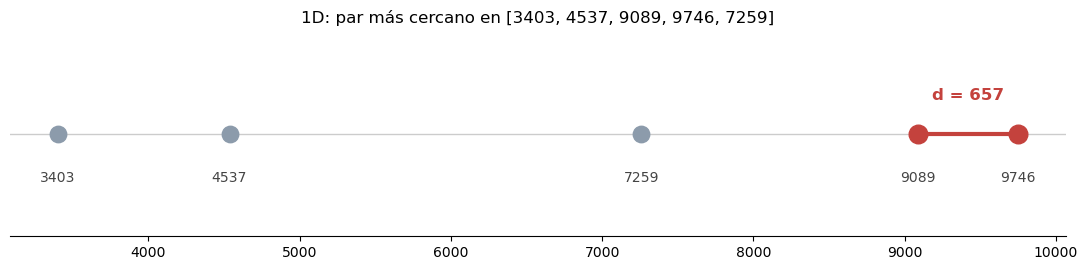

In [12]:
# =====================================================================
# 📊 VISUALIZACIÓN 1D: los puntos sobre la recta y el par más cercano
# =====================================================================
# %matplotlib inline le dice a Jupyter que incruste las graficas como
# imagenes DENTRO del notebook. Sin esta linea, en algunos entornos
# plt.show() no muestra nada (el backend por defecto no es interactivo)
%matplotlib inline
import matplotlib.pyplot as plt

# Criterio de color para TODAS las gráficas de la actividad:
#   - gris apagado  = el conjunto de puntos (contexto)
#   - rojo intenso  = el par más cercano (el resultado, lo único que debe
#                     llamar la atención). Un solo color de acento evita
#                     que la gráfica se convierta en un arcoíris ilegible
COLOR_FONDO = '#8C9BAB'
COLOR_ACENTO = '#C4423D'

fig, ax = plt.subplots(figsize=(11, 2.8))

# En 1D los puntos viven en una recta -> los pintamos todos a altura y=0
ax.scatter(LISTA_1D_EJEMPLO, [0] * len(LISTA_1D_EJEMPLO),
           s=140, color=COLOR_FONDO, zorder=2)

# Recalculamos el par más cercano del ejemplo para resaltarlo
par_ej, dist_ej = par_mas_cercano_1d_optimo(LISTA_1D_EJEMPLO)
ax.scatter(par_ej, [0, 0], s=180, color=COLOR_ACENTO, zorder=3)

# Línea que une el par ganador + etiqueta con su distancia
ax.plot(par_ej, [0, 0], color=COLOR_ACENTO, linewidth=3, zorder=2)
ax.annotate(f'd = {dist_ej}', xy=(sum(par_ej) / 2, 0), xytext=(sum(par_ej) / 2, 0.05),
            ha='center', color=COLOR_ACENTO, fontsize=12, fontweight='bold')

# Etiqueta con el valor de cada punto, para leer la gráfica sin esfuerzo
for p in LISTA_1D_EJEMPLO:
    ax.annotate(str(p), xy=(p, 0), xytext=(p, -0.07),
                ha='center', fontsize=10, color='#444444')

# La recta numérica de referencia
ax.axhline(0, color='#CCCCCC', linewidth=1, zorder=1)

# Limpieza visual: en esta gráfica el eje y no significa nada -> fuera
ax.set_ylim(-0.15, 0.15)
ax.set_yticks([])
ax.spines[['left', 'top', 'right']].set_visible(False)
ax.set_title(f'1D: par más cercano en {LISTA_1D_EJEMPLO}')
plt.tight_layout()
plt.show()

---

## Paso 3 — Extender el algoritmo a 2D

### 📌 Enunciado
Extender el algoritmo a puntos del plano: `[(1122, 6175), (135, 4076), (7296, 2741), ...]`

### 💡 Idea de la solución

**¿Qué cambia respecto a 1D?**
- Cada punto ahora es una tupla `(x, y)`
- La distancia ya no es un valor absoluto, sino la **distancia euclídea**: $d = \sqrt{(x_1-x_2)^2 + (y_1-y_2)^2}$

**La fuerza bruta se extiende sin esfuerzo:** el doble bucle es idéntico, solo cambia la función de distancia. La programaremos de forma **genérica** (válida para 2D, 3D o cualquier dimensión) y nos servirá como "juez" para verificar que el Divide y Vencerás da el resultado correcto.

**El Divide y Vencerás requiere más cuidado en el paso de COMBINAR:**

1. Ordenamos los puntos por su coordenada **x** y dividimos con una **línea vertical** por el punto medio (en 1D el corte era un punto; en 2D es una línea)
2. Resolvemos cada mitad recursivamente (idéntico a 1D)
3. La **franja** ahora es una **banda vertical** del plano: los puntos con `|x - x_medio| < mejor_distancia`. Igual que en 1D, cualquier pareja que cruce la línea y mejore el resultado debe tener sus dos puntos dentro de esa banda
4. **El problema nuevo de 2D:** dentro de la franja puede haber muchos puntos con x parecida pero y muy distinta (una "columna" de puntos). Compararlos todos contra todos podría volver a ser O(n²). **La solución:** ordenar la franja por **y** y comparar cada punto solo con los siguientes mientras su diferencia en y sea menor que `mejor_distancia`. Un argumento geométrico clásico (en un rectángulo de `2d × d` no caben más de 8 puntos separados entre sí al menos `d`) garantiza que cada punto se compara **como mucho con 7 vecinos** -> el paso de combinar sigue siendo lineal

En el código, la comparación de la franja incluye un `break` que es exactamente esa poda: al estar ordenada por y, en cuanto un candidato queda demasiado lejos en y, todos los siguientes también lo estarán.

In [13]:
# =====================================================================
# PASO 3 - RESOLUCIÓN (parte 1): DISTANCIA EUCLÍDEA Y FUERZA BRUTA
# =====================================================================

def distancia_euclidea(p1, p2):
    """
    Distancia euclídea entre dos puntos de CUALQUIER dimensión.

    zip(p1, p2) empareja coordenada a coordenada:
      p1=(x1,y1), p2=(x2,y2)  ->  (x1,x2), (y1,y2)
    y para cada pareja calculamos (a-b)^2. La suma de esos cuadrados,
    con raíz final, es exactamente la fórmula de Pitágoras generalizada:
      2D: sqrt((x1-x2)^2 + (y1-y2)^2)
      3D: sqrt((x1-x2)^2 + (y1-y2)^2 + (z1-z2)^2)
    Al escribirla así, LA MISMA función sirve para 2D, 3D, 4D...
    """
    return math.sqrt(sum((a - b) ** 2 for a, b in zip(p1, p2)))


def par_mas_cercano_nd_fuerza_bruta(puntos):
    """
    Fuerza bruta genérica: EXACTAMENTE la misma estructura de doble bucle
    que en 1D, cambiando solo la función de distancia. Sigue siendo O(n^2).
    La usaremos como referencia ("juez") para verificar que las versiones
    de Divide y Vencerás dan el resultado correcto.
    """
    n = len(puntos)
    mejor_distancia = float('inf')
    mejor_par = None

    for i in range(n):
        for j in range(i + 1, n):
            d = distancia_euclidea(puntos[i], puntos[j])
            if d < mejor_distancia:
                mejor_distancia = d
                mejor_par = (puntos[i], puntos[j])

    return mejor_par, mejor_distancia


# ---------------------------------------------------------------------
# 🔍 COMPROBACIÓN con el ejemplo del enunciado
# ---------------------------------------------------------------------
LISTA_2D_EJEMPLO = [(1122, 6175), (135, 4076), (7296, 2741)]

par, dist = par_mas_cercano_nd_fuerza_bruta(LISTA_2D_EJEMPLO)
print(f"Puntos: {LISTA_2D_EJEMPLO}")
print(f"Par más cercano (fuerza bruta 2D): {par}")
print(f"Distancia euclídea: {dist:.4f}")

Puntos: [(1122, 6175), (135, 4076), (7296, 2741)]
Par más cercano (fuerza bruta 2D): ((1122, 6175), (135, 4076))
Distancia euclídea: 2319.4762


In [14]:
# =====================================================================
# PASO 3 - RESOLUCIÓN (parte 2): DIVIDE Y VENCERÁS EN 2D
# (algoritmo clásico "Closest Pair of Points")
# =====================================================================

def _dyv_2d(puntos_por_x):
    """
    Recibe los puntos YA ORDENADOS por x. La estructura es un calco de
    la versión 1D; los comentarios señalan lo que cambia.
    """
    n = len(puntos_por_x)

    # CASO BASE: idéntico a 1D -> pocos puntos, fuerza bruta directa
    if n <= 3:
        return par_mas_cercano_nd_fuerza_bruta(puntos_por_x)

    # DIVIDIR: ahora el corte es una LÍNEA VERTICAL x = x_medio.
    # Como los puntos vienen ordenados por x, partir la lista por la
    # mitad deja a un lado los de x pequeña y al otro los de x grande
    medio = n // 2
    x_medio = puntos_por_x[medio][0]   # [0] = coordenada x del punto medio
    izquierda = puntos_por_x[:medio]
    derecha = puntos_por_x[medio:]

    # VENCER: recursión sobre cada mitad, igual que en 1D
    par_izq, dist_izq = _dyv_2d(izquierda)
    par_der, dist_der = _dyv_2d(derecha)

    # Mejor resultado provisional = mejor de las dos mitades
    if dist_izq <= dist_der:
        mejor_par, mejor_distancia = par_izq, dist_izq
    else:
        mejor_par, mejor_distancia = par_der, dist_der

    # COMBINAR (aquí está TODA la diferencia con 1D):
    #
    # (a) La franja es una BANDA VERTICAL: puntos a menos de
    #     mejor_distancia de la línea de corte, a cualquiera de los dos lados
    franja = [p for p in puntos_por_x if abs(p[0] - x_medio) < mejor_distancia]

    # (b) Ordenamos la franja por y ([1] = coordenada y). Este es el truco
    #     clave de 2D: permite recorrer los candidatos "de abajo a arriba"
    franja.sort(key=lambda p: p[1])

    # (c) Cada punto de la franja se compara solo con los SIGUIENTES en y.
    #     El 'break' es la poda: si el siguiente punto ya está a más de
    #     mejor_distancia en vertical, la distancia euclídea será aún mayor
    #     (y lo mismo para todos los que vienen detrás, porque están
    #     ordenados) -> no tiene sentido seguir comparando.
    #     Gracias a esta poda, cada punto se compara con un puñado de
    #     vecinos (máximo 7 en teoría), no con toda la franja
    for i in range(len(franja)):
        for j in range(i + 1, len(franja)):
            if (franja[j][1] - franja[i][1]) >= mejor_distancia:
                break  # poda: ya no puede haber más candidatos útiles
            d = distancia_euclidea(franja[i], franja[j])
            if d < mejor_distancia:
                mejor_distancia = d
                mejor_par = (franja[i], franja[j])

    return mejor_par, mejor_distancia


def par_mas_cercano_2d_dyv(puntos):
    # Paso previo (como el sorted() de 1D): ordenar por la coordenada x.
    # key=lambda p: p[0] significa "usa la x de cada punto como criterio"
    puntos_por_x = sorted(puntos, key=lambda p: p[0])
    return _dyv_2d(puntos_por_x)


# ---------------------------------------------------------------------
# 🔍 COMPROBACIÓN 1: ejemplo del enunciado -> debe coincidir con la
# fuerza bruta de la celda anterior
# ---------------------------------------------------------------------
par, dist = par_mas_cercano_2d_dyv(LISTA_2D_EJEMPLO)
print(f"Divide y Vencerás 2D: {par}, distancia = {dist:.4f}")

# ---------------------------------------------------------------------
# 🔍 COMPROBACIÓN 2: 1000 puntos aleatorios, midiendo tiempos.
# La fuerza bruta hace de "juez": si ambas distancias coinciden,
# el Divide y Vencerás es correcto
# ---------------------------------------------------------------------
random.seed(42)
LISTA_2D = [(random.randrange(1, 10000), random.randrange(1, 10000)) for _ in range(1000)]

t0 = time.time()
par_fb, dist_fb = par_mas_cercano_nd_fuerza_bruta(LISTA_2D)
t_fb = time.time() - t0

t0 = time.time()
par_dyv, dist_dyv = par_mas_cercano_2d_dyv(LISTA_2D)
t_dyv = time.time() - t0

print(f"\nCon {len(LISTA_2D)} puntos aleatorios en 2D:")
print(f"  Fuerza bruta      -> d = {dist_fb:.4f}  (tiempo: {t_fb:.4f}s)")
print(f"  Divide y Vencerás -> d = {dist_dyv:.4f}  (tiempo: {t_dyv:.4f}s)")
print(f"\n¿Coinciden? {math.isclose(dist_fb, dist_dyv)}")
print(f"El Divide y Vencerás fue ~{t_fb/max(t_dyv, 1e-9):.0f} veces más rápido")

Divide y Vencerás 2D: ((135, 4076), (1122, 6175)), distancia = 2319.4762



Con 1000 puntos aleatorios en 2D:
  Fuerza bruta      -> d = 9.0000  (tiempo: 0.3150s)
  Divide y Vencerás -> d = 9.0000  (tiempo: 0.0027s)

¿Coinciden? True
El Divide y Vencerás fue ~115 veces más rápido


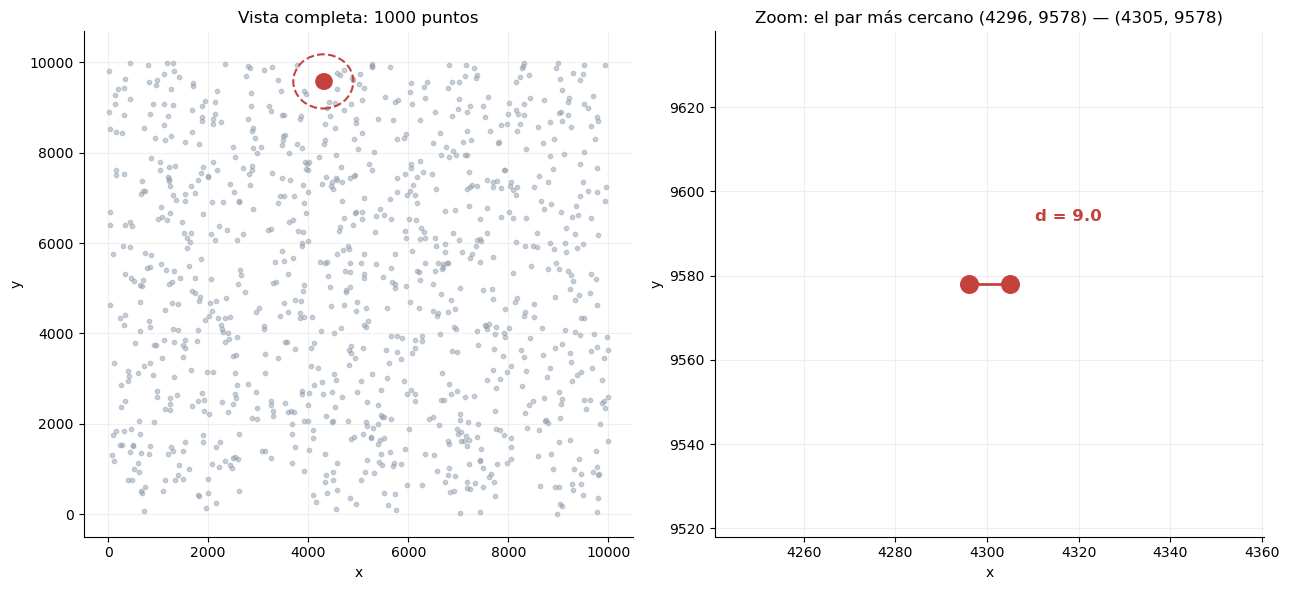

In [15]:
# =====================================================================
# 📊 VISUALIZACIÓN 2D: los 1000 puntos y el par más cercano resaltado
# =====================================================================
# Dos vistas de lo mismo:
#   - Izquierda: el plano completo. El par ganador está marcado en rojo
#     (a esta escala los dos puntos se ven casi como uno solo: ¡están a
#     distancia 9 en un plano de 10000 x 10000!)
#   - Derecha: zoom sobre la zona del par, para ver los dos puntos
#     claramente separados y su distancia

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))

p1, p2 = par_dyv  # el par que encontró el Divide y Vencerás en la celda anterior

# --- Vista completa ---
xs = [p[0] for p in LISTA_2D]
ys = [p[1] for p in LISTA_2D]
ax1.scatter(xs, ys, s=10, color=COLOR_FONDO, alpha=0.45)
ax1.scatter([p1[0], p2[0]], [p1[1], p2[1]], s=120, color=COLOR_ACENTO, zorder=3)
# Un círculo alrededor del par para poder localizarlo a simple vista
circulo = plt.Circle(((p1[0]+p2[0])/2, (p1[1]+p2[1])/2), 600,
                     fill=False, color=COLOR_ACENTO, linewidth=1.5, linestyle='--')
ax1.add_patch(circulo)
ax1.set_title(f'Vista completa: {len(LISTA_2D)} puntos')
ax1.set_xlabel('x'); ax1.set_ylabel('y')

# --- Zoom sobre el par ganador ---
cx, cy = (p1[0]+p2[0])/2, (p1[1]+p2[1])/2   # centro del par
radio = 60                                    # media ventana del zoom
# Puntos del entorno (para ver que no hay ningún otro más cerca)
vecinos = [p for p in LISTA_2D if abs(p[0]-cx) < radio and abs(p[1]-cy) < radio]
ax2.scatter([p[0] for p in vecinos], [p[1] for p in vecinos],
            s=60, color=COLOR_FONDO, alpha=0.7)
ax2.scatter([p1[0], p2[0]], [p1[1], p2[1]], s=160, color=COLOR_ACENTO, zorder=3)
ax2.plot([p1[0], p2[0]], [p1[1], p2[1]], color=COLOR_ACENTO, linewidth=2)
ax2.annotate(f'd = {dist_dyv:.1f}', xy=(cx, cy), xytext=(cx + 10, cy + 15),
             color=COLOR_ACENTO, fontsize=12, fontweight='bold')
ax2.set_xlim(cx - radio, cx + radio)
ax2.set_ylim(cy - radio, cy + radio)
ax2.set_title(f'Zoom: el par más cercano {p1} — {p2}')
ax2.set_xlabel('x'); ax2.set_ylabel('y')

for ax in (ax1, ax2):
    ax.grid(True, alpha=0.2)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()

### ⏱️ Complejidad en 2D

En cada nivel de la recursión hacemos dos subproblemas de tamaño mitad, más el trabajo de combinar, que en esta versión incluye **ordenar la franja por y** (`O(n log n)`):

$$T(n) = 2·T(n/2) + O(n \log n) \implies T(n) = O(n \log^2 n)$$

**¿Se puede mejorar?** Sí: la versión "de libro de texto" mantiene una segunda copia de los puntos pre-ordenada por y y la va **fusionando** al estilo *merge sort* en vez de reordenar la franja en cada llamada. Con ello el paso de combinar baja a `O(n)` y el total a **O(n log n)**. Aquí mantenemos la versión con `sort` dentro porque es mucho más fácil de leer y la diferencia práctica con 1000 puntos es inapreciable — pero es importante saber que existe esa mejora.

---

## Paso 4 — Extender el algoritmo a 3D

### 📌 Enunciado
Extender el algoritmo anterior a tres dimensiones `(x, y, z)`.

### 💡 Idea de la solución

La estructura del algoritmo **no cambia en absoluto** — esa es la belleza de Divide y Vencerás:

- Se sigue ordenando y dividiendo por la coordenada **x** (el corte ahora es un **plano vertical** en vez de una línea)
- La franja sigue siendo "puntos con `|x - x_medio| < mejor_distancia`" (ahora es una **rebanada** del espacio 3D)
- `distancia_euclidea` ya era genérica, así que sirve tal cual

**Lo único que cambia es cómo revisar la franja.** En 2D bastaba con ordenar por y y mirar ~7 vecinos. En 3D los puntos de la franja "compiten" en dos coordenadas a la vez (y **y** z), así que la poda de una sola ordenación ya no basta por sí sola. La teoría dice que sigue existiendo una cota constante de vecinos (el mismo argumento de empaquetado, ahora con cajas 3D) y que O(n log n) es alcanzable, pero implementarlo es bastante más laborioso.

**Decisión de diseño para esta actividad:** revisar la franja por fuerza bruta. Es una simplificación razonable porque:
- La franja normalmente contiene **muchos menos puntos** que el conjunto total -> en la práctica sigue siendo mucho más rápido que la fuerza bruta global (lo comprobaremos midiendo tiempos)
- Mantiene el código legible y centrado en la idea de Divide y Vencerás, que es el objetivo de la actividad
- El precio: en el **peor caso teórico** (datos degenerados con casi todos los puntos apilados junto al plano de corte) no se garantiza el O(n log n) estricto

Además, al escribir la función de forma genérica (`_dyv_nd`), la misma implementación resuelve 2D, 3D o cualquier dimensión.

In [16]:
# =====================================================================
# PASO 4 - RESOLUCIÓN: DIVIDE Y VENCERÁS EN 3D (Y CUALQUIER DIMENSIÓN)
# =====================================================================

def _dyv_nd(puntos_por_x):
    """
    Versión GENÉRICA del Divide y Vencerás: funciona con tuplas de
    cualquier longitud (2D, 3D, 4D...) porque:
      - solo usa explícitamente la coordenada [0] (la x) para dividir
      - distancia_euclidea ya funciona en cualquier dimensión
    Comparar con _dyv_2d: la ÚNICA diferencia es cómo se revisa la franja.
    """
    n = len(puntos_por_x)

    # CASO BASE: idéntico a los anteriores
    if n <= 3:
        return par_mas_cercano_nd_fuerza_bruta(puntos_por_x)

    # DIVIDIR: corte por un plano vertical x = x_medio
    medio = n // 2
    x_medio = puntos_por_x[medio][0]
    izquierda = puntos_por_x[:medio]
    derecha = puntos_por_x[medio:]

    # VENCER: recursión sobre cada mitad
    par_izq, dist_izq = _dyv_nd(izquierda)
    par_der, dist_der = _dyv_nd(derecha)

    if dist_izq <= dist_der:
        mejor_par, mejor_distancia = par_izq, dist_izq
    else:
        mejor_par, mejor_distancia = par_der, dist_der

    # COMBINAR: la franja es la "rebanada" del espacio pegada al plano
    # de corte. Se revisa por fuerza bruta (ver justificación en la celda
    # anterior): como la franja suele tener pocos puntos, en la práctica
    # sigue siendo muy rápido
    franja = [p for p in puntos_por_x if abs(p[0] - x_medio) < mejor_distancia]

    for i in range(len(franja)):
        for j in range(i + 1, len(franja)):
            d = distancia_euclidea(franja[i], franja[j])
            if d < mejor_distancia:
                mejor_distancia = d
                mejor_par = (franja[i], franja[j])

    return mejor_par, mejor_distancia


def par_mas_cercano_nd_dyv(puntos):
    # Igual que siempre: ordenar por x antes de empezar
    puntos_por_x = sorted(puntos, key=lambda p: p[0])
    return _dyv_nd(puntos_por_x)


# ---------------------------------------------------------------------
# 🔍 COMPROBACIÓN 1: 1000 puntos aleatorios en 3D, con la fuerza bruta
# genérica como juez y midiendo tiempos
# ---------------------------------------------------------------------
random.seed(42)
LISTA_3D = [(random.randrange(1, 10000), random.randrange(1, 10000), random.randrange(1, 10000))
            for _ in range(1000)]

t0 = time.time()
par_fb, dist_fb = par_mas_cercano_nd_fuerza_bruta(LISTA_3D)
t_fb = time.time() - t0

t0 = time.time()
par_dyv, dist_dyv = par_mas_cercano_nd_dyv(LISTA_3D)
t_dyv = time.time() - t0

print(f"Con {len(LISTA_3D)} puntos aleatorios en 3D:")
print(f"  Fuerza bruta      -> d = {dist_fb:.4f}  (tiempo: {t_fb:.4f}s)")
print(f"    par: {par_fb}")
print(f"  Divide y Vencerás -> d = {dist_dyv:.4f}  (tiempo: {t_dyv:.4f}s)")
print(f"    par: {par_dyv}")
print(f"\n¿Coinciden? {math.isclose(dist_fb, dist_dyv)}")

# ---------------------------------------------------------------------
# 🔍 COMPROBACIÓN 2: como _dyv_nd es genérica, la misma función resuelve
# también el ejemplo 2D del enunciado (mismo resultado que antes)
# ---------------------------------------------------------------------
par_2d, dist_2d = par_mas_cercano_nd_dyv(LISTA_2D_EJEMPLO)
print(f"\nLa misma función genérica aplicada al ejemplo 2D: {par_2d}, d = {dist_2d:.4f}")

Con 1000 puntos aleatorios en 3D:
  Fuerza bruta      -> d = 76.5572  (tiempo: 0.3761s)
    par: ((8891, 7634, 6813), (8890, 7570, 6771))
  Divide y Vencerás -> d = 76.5572  (tiempo: 0.0377s)
    par: ((8890, 7570, 6771), (8891, 7634, 6813))

¿Coinciden? True

La misma función genérica aplicada al ejemplo 2D: ((135, 4076), (1122, 6175)), d = 2319.4762


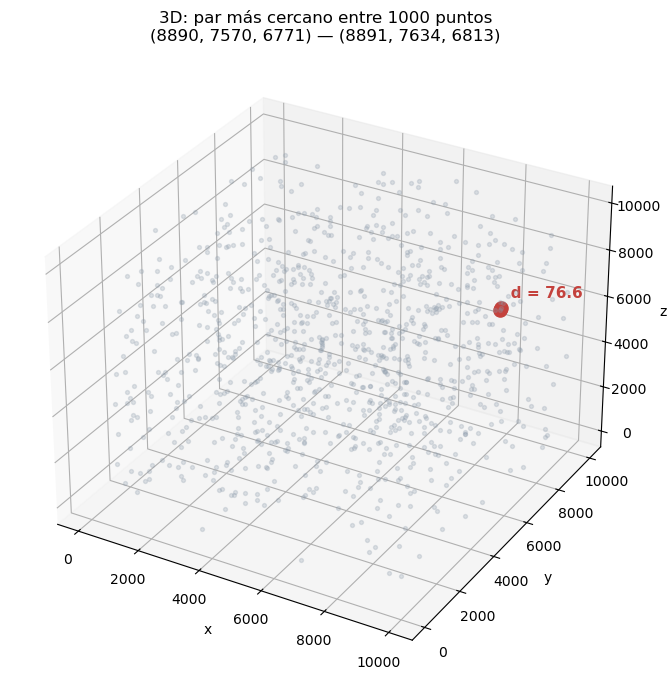

In [17]:
# =====================================================================
# 📊 VISUALIZACIÓN 3D: los 1000 puntos y el par más cercano resaltado
# =====================================================================
# Cómo leer la gráfica:
#   - Puntos grises pequeños y semitransparentes = el conjunto completo
#     (apagados a propósito: son el "fondo", no el mensaje)
#   - Puntos rojos grandes unidos por una línea = el par más cercano
#     que encontró el algoritmo (el único mensaje de la gráfica)

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')

# Separamos las coordenadas x, y, z de cada tupla para poder pintarlas.
# zip(*LISTA_3D) "transpone" la lista: de [(x,y,z), ...] a ([x...], [y...], [z...])
xs, ys, zs = zip(*LISTA_3D)
ax.scatter(xs, ys, zs, s=8, color=COLOR_FONDO, alpha=0.25, depthshade=False)

# El par más cercano calculado por el Divide y Vencerás en la celda anterior
p1, p2 = par_dyv
ax.scatter(*zip(p1, p2), s=90, color=COLOR_ACENTO, depthshade=False)
ax.plot(*zip(p1, p2), color=COLOR_ACENTO, linewidth=2)

# Etiqueta directa sobre el par (mejor que una leyenda: señala el dato exacto)
ax.text(p1[0], p1[1], p1[2] + 500, f"  d = {dist_dyv:.1f}",
        color=COLOR_ACENTO, fontsize=11, fontweight='bold')

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')
ax.set_title(f'3D: par más cercano entre {len(LISTA_3D)} puntos\n{p1} — {p2}')
plt.tight_layout()
plt.show()

# Nota: en 3D es difícil APRECIAR visualmente que ese par es el más cercano
# (la perspectiva engaña), y justamente por eso el algoritmo importa:
# a partir de 2-3 dimensiones ya no podemos fiarnos del ojo.

---

## ✅ Conclusiones de la actividad extra

### ¿Se resolvió todo lo que pedía la guía?

| Punto de la guía | Dónde se resuelve | Resultado |
|---|---|---|
| 1D — fuerza bruta | Paso 1 | O(n²), verificado con el ejemplo del enunciado |
| 1D — calcular complejidad, ¿mejora? | Tras el Paso 1 | O(n²) -> sí se puede mejorar organizando los datos |
| 1D — Divide y Vencerás | Paso 2 | O(n log n), con traza de la recursión visible |
| 1D — complejidad, ¿mejora? | Tras el Paso 2 | Sí: en 1D basta ordenar + una pasada (vecinos consecutivos) |
| Extender a 2D | Paso 3 | Franja ordenada por y + poda de vecinos; verificado contra fuerza bruta |
| Extender a 3D | Paso 4 | Versión genérica n-dimensional; verificada contra fuerza bruta |
| Visualización 1D / 2D / 3D | Gráficas de cada paso | El par más cercano resaltado sobre el conjunto de puntos |

### Resumen de complejidades

| Caso | Fuerza bruta | Divide y Vencerás |
|---|---|---|
| **1D** | O(n²) | O(n log n); y en 1D existe la mejora específica de comparar solo consecutivos tras ordenar (búsqueda O(n)) |
| **2D** | O(n²) | **O(n log² n)** tal y como está implementado (se reordena la franja en cada llamada); O(n log n) en la versión de libro que fusiona al estilo *merge sort* |
| **3D / n-D** | O(n²) | O(n log n) alcanzable en teoría; nuestra versión revisa la franja por fuerza bruta -> muy rápida en la práctica, sin garantía estricta en el peor caso |

### Idea final

La clave de Divide y Vencerás es la misma que en las Torres de Hanói: **reducir el problema a subproblemas más pequeños del mismo tipo** (la recursión hace el trabajo pesado) **y concentrar el ingenio en el paso de combinar**. Aquí, la franja central es el equivalente a "mover el disco grande" en Hanói: es el único momento en que hay que razonar sobre el problema completo; todo lo demás se resuelve solo.

Y una lección práctica importante: al pasar de 1D a 2D y 3D, lo que se complica **no es dividir ni vencer, sino combinar** — la geometría de la franja es cada vez más delicada. Por eso la fuerza bruta, aunque lenta, sigue teniendo un papel: es el "juez" sencillo y seguro contra el que verificamos que el algoritmo rápido es correcto.